# Week 10 — The Watchers
## COMP 3200 — Deep Learning

This week, we built a CNN from scratch to classify handwritten digits from the MNIST dataset. Rather than treating every pixel independently, our network uses 16 shared 3x3 kernels to identify local patterns throughout each image. We implemented patch extraction, the convolutional forward pass, backpropagation, and training. We visualized the learned kernels and tested the network to verify that it performs correctly.

## Part 1 — Slice the Image into Patches - Brady

We created a function called `get_patches()` that extracts every 3x3 section of an image. Since each MNIST image is 28x28, moving the window one pixel at a time produces 676 patches per image. Each patch is flattened into 9 values so it can be multiplied by the kernels during convolution.

In [1]:
import numpy as np

def get_patches(layer):
    batch_size = layer.shape[0]
    patches = []

    for r in range(layer.shape[1] - 3 + 1):
        for c in range(layer.shape[2] - 3 + 1):
            patch = layer[:, r:r+3, c:c+3]
            patches.append(patch.reshape(batch_size, 1, 3, 3))

    expanded = np.concatenate(patches, axis=1)
    es = expanded.shape

    return expanded.reshape(es[0] * es[1], 9), es

In [2]:
images = np.zeros((3, 28, 28))

flat_patches, es = get_patches(images)

print("Original image shape:", images.shape)
print("Flattened patches shape:", flat_patches.shape)
print("Expanded patches shape:", es)

Original image shape: (3, 28, 28)
Flattened patches shape: (2028, 9)
Expanded patches shape: (3, 676, 3, 3)


## Part 2 — Convolution Forward Pass - Kevin

In this part, we created 16 kernels, each containing 9 weights. The kernels are applied to every 3x3 patch using matrix multiplication, allowing the network to recognize patterns throughout an image. We then reshape the results and apply the tanh activation function. This produces 10,816 hidden values per image, which are passed through dropout and a softmax classifier to predict the digit.

In [3]:
def init_kernels():
    return 0.02 * np.random.random((9, 16)) - 0.01


def conv_forward(layer_0, kernels, W_1_2=None, mask=None):
    # Use actual batch size n to handle smaller last batch
    n = layer_0.shape[0]

    # Extract patches: (n * 676, 9)
    flat_patches, es = get_patches(layer_0)

    # Dot product with 16 kernels: (n * 676, 16)
    kernel_out = flat_patches.dot(kernels)

    # Reshape per image and apply tanh: (n, 10816)
    layer_1_raw = np.tanh(kernel_out.reshape(n, 676 * 16))

    # Save slope before dropout
    slope = 1.0 - layer_1_raw ** 2

    # Apply dropout mask and survivor scaling
    if mask is not None:
        layer_1 = layer_1_raw * mask * 2
    else:
        layer_1 = layer_1_raw

    # Softmax classifier output if W_1_2 is provided
    layer_2 = None
    if W_1_2 is not None:
        logits = layer_1.dot(W_1_2)
        exp_scores = np.exp(logits - np.max(logits, axis=1, keepdims=True))
        layer_2 = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    return flat_patches, kernel_out, layer_1, slope, layer_2

In [4]:
images = np.zeros((3, 28, 28))
kernels = init_kernels()

flat_patches, kernel_out, layer_1, slope, layer_2 = conv_forward(
    images, kernels
)

print("Kernel shape:", kernels.shape)
print("Convolution output shape:", kernel_out.shape)
print("Hidden layer shape:", layer_1.shape)
print("Activation range:", layer_1.min(), "to", layer_1.max())

Kernel shape: (9, 16)
Convolution output shape: (2028, 16)
Hidden layer shape: (3, 10816)
Activation range: 0.0 to 0.0


The forward pass produced 10,816 hidden values for each image using 16 shared kernels. The output values were passed through tanh, which keeps them between -1 and 1. This confirms that our convolutional layer produces the expected dimensions before training.

## Part 3 — Backpropagation and Training - Robert

In this part, we trained our convolutional network to recognize handwritten digits using the MNIST dataset. We implemented backpropogation to update both the kernels and the dense layer weights. The network trains on 1,000 images for 300 epochs using a learning rate of 0.02 and batches of 128. We also track validation accuracy to measure how well the network generalizes to images it has not trained on.

In [5]:
from data import load_mnist, one_hot
from forms import tanh, tanh_deriv, softmax


def train_step(layer_0, Y_batch, kernels, W_1_2, mask, alpha):

    # Get all 3x3 patches
    flat_patches, patch_shape = get_patches(layer_0)

    # Convolution
    kernel_out = flat_patches.dot(kernels)

    # Flatten into one vector per image
    layer_1 = kernel_out.reshape(layer_0.shape[0], -1)

    # Activation
    layer_1 = tanh(layer_1)

    # Derivative before dropout
    slope = tanh_deriv(layer_1)

    # Dropout
    layer_1 *= mask * 2

    # Output layer
    layer_2 = softmax(layer_1.dot(W_1_2))

    # Backpropagation
    delta_2 = (layer_2 - Y_batch) / layer_0.shape[0]
    delta_1 = delta_2.dot(W_1_2.T) * slope
    delta_1 *= mask * 2

    W_1_2 -= alpha * layer_1.T.dot(delta_2)

    delta_1_reshaped = delta_1.reshape(kernel_out.shape)
    k_update = flat_patches.T.dot(delta_1_reshaped)

    kernels -= alpha * k_update

    return k_update

In [6]:
(X_train, y_train), (X_test, y_test) = load_mnist()

X_train = X_train.reshape(-1, 28, 28)
X_test = X_test.reshape(-1, 28, 28)

X_val = X_train[1000:2000]
Y_val = one_hot(y_train[1000:2000])

X_train = X_train[:1000]
Y_train = one_hot(y_train[:1000])

Y_test = one_hot(y_test)

np.random.seed(1)

alpha = 0.02
epochs = 300
batch_size = 128

kernels = 0.02 * np.random.random((9, 16)) - 0.01

hidden_size = 26 * 26 * 16
W_1_2 = 0.2 * np.random.random((hidden_size, 10)) - 0.1

val_accuracies = []

In [7]:
for epoch in range(epochs):

    for s in range(0, len(X_train), batch_size):

        layer_0 = X_train[s:s + batch_size]
        Y_batch = Y_train[s:s + batch_size]

        mask = np.random.randint(
            2, size=(len(layer_0), hidden_size)
        )

        train_step(
            layer_0, Y_batch, kernels, W_1_2, mask, alpha
        )

    flat_patches, patch_shape = get_patches(X_val)
    kernel_out = flat_patches.dot(kernels)

    val_hidden = tanh(
        kernel_out.reshape(X_val.shape[0], -1)
    )

    val_scores = val_hidden.dot(W_1_2)

    val_predictions = np.argmax(val_scores, axis=1)
    val_actual = np.argmax(Y_val, axis=1)

    val_accuracy = np.mean(
        val_predictions == val_actual
    ) * 100

    val_accuracies.append(val_accuracy)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

Epoch 10/300, Validation Accuracy: 68.20%
Epoch 20/300, Validation Accuracy: 82.30%
Epoch 30/300, Validation Accuracy: 84.00%
Epoch 40/300, Validation Accuracy: 84.90%
Epoch 50/300, Validation Accuracy: 86.10%
Epoch 60/300, Validation Accuracy: 86.40%
Epoch 70/300, Validation Accuracy: 86.90%
Epoch 80/300, Validation Accuracy: 86.50%
Epoch 90/300, Validation Accuracy: 87.00%
Epoch 100/300, Validation Accuracy: 87.40%
Epoch 110/300, Validation Accuracy: 87.40%
Epoch 120/300, Validation Accuracy: 87.70%
Epoch 130/300, Validation Accuracy: 87.70%
Epoch 140/300, Validation Accuracy: 88.00%
Epoch 150/300, Validation Accuracy: 88.20%
Epoch 160/300, Validation Accuracy: 87.90%
Epoch 170/300, Validation Accuracy: 87.40%
Epoch 180/300, Validation Accuracy: 87.60%
Epoch 190/300, Validation Accuracy: 87.70%
Epoch 200/300, Validation Accuracy: 87.60%
Epoch 210/300, Validation Accuracy: 87.60%
Epoch 220/300, Validation Accuracy: 87.70%
Epoch 230/300, Validation Accuracy: 87.50%
Epoch 240/300, Valid

## Part 4 — Visualizing the Learned Kernels - Elijah

In this part, we visualized the 16 kernels that our network learned during training. Each kernel contains 9 weights that can be reshaped into a 3x3 image. Displaying the kernels allows us to examine the patterns the network learned to recognize, such as edges, corners, and other small features.

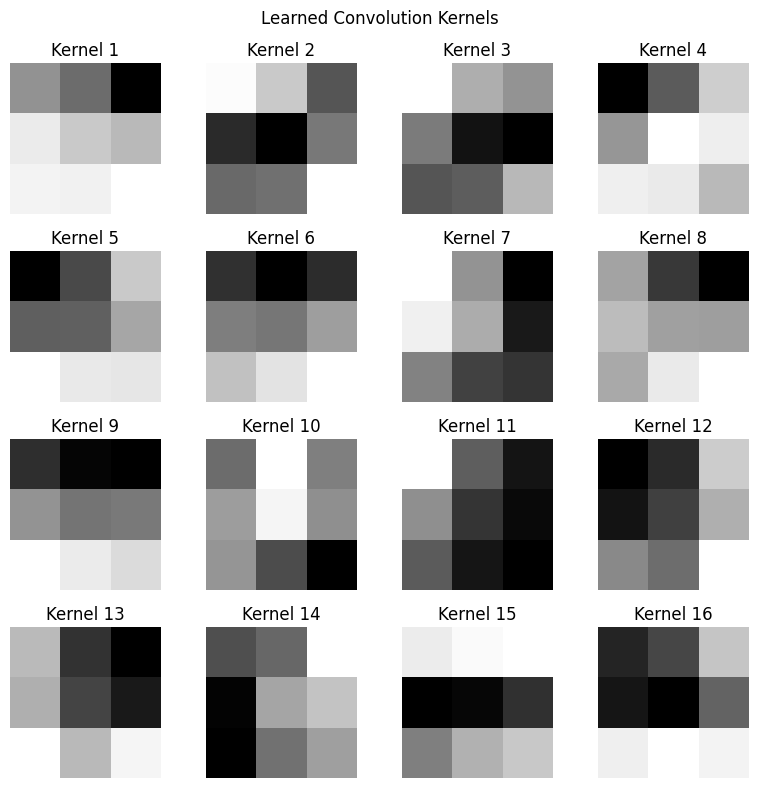

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i in range(16):
    kernel = kernels[:, i].reshape(3, 3)

    ax = axes[i // 4, i % 4]
    ax.imshow(kernel, cmap="gray")
    ax.set_title(f"Kernel {i + 1}")
    ax.axis("off")

plt.suptitle("Learned Convolution Kernels")
plt.tight_layout()
plt.savefig("kernels.png")
plt.show()

## Part 5 — Testing the Network - Colson

In this part, I wrote five tests to verify that our convolutional network works correctly. The tests check the dimensions and contents of the extracted patches, the shape and activation values of the forward pass, and the accuracy of the gradients calculated during backpropagation. We also tested whether the network could learn by training it for 30 epochs and checking that its validation accuracy exceeded 50%. All five tests passed.

In [9]:
from test_watchers import (
    test_patch_shape,
    test_patch_content,
    test_forward_shape,
    test_training_step,
    test_it_learns
)

tests = [
    test_patch_shape,
    test_patch_content,
    test_forward_shape,
    test_training_step,
    test_it_learns
]

for test in tests:
    try:
        test()
        print(f"PASS: {test.__name__}")
    except Exception as e:
        print(f"FAIL: {test.__name__} - {e}")

PASS: test_patch_shape
PASS: test_patch_content
PASS: test_forward_shape
PASS: test_training_step
PASS: test_it_learns


## Week 9 vs. Week 10 — Network Comparison

In Week 9, we trained a dense neural network that connected every input pixel to the hidden layer. In Week 10, we replaced that first layer with 16 shared convolutional kernels. This greatly reduced the number of first-layer weights, but the convolutional network still requires a large dense classifier after flattening the feature maps.

The following table compares the number of weights and final test accuracy of both networks.

| Metric | Week 9 — Dense | Week 10 — CNN |
|---|---:|---:|
| First-layer weights | 78,400 | 144 |
| Total weights | 79,400 | 108,304 |
| Final test accuracy | 86.3% | 87.1% |

The convolutional network reduced the first layer from 78,400 weights to only 144 because each kernel shares its weights across every image position. However, the CNN has more total weights than the dense network because its final classifier connects 10,816 hidden values to 10 output neurons. We can compare the test accuracies to determine whether weight sharing improved generalization, rather than assuming that fewer first-layer weights automatically produces better results.

## Part 6 — Holocron Reading - Colson

The biggest difference between our Week 9 and Week 10 networks was how they learned patterns from images. In Week 9, our dense network needed 78,400 weights in its first layer because every pixel connected to each hidden neuron. With convalution, we only needed the 144 first-layer weights because the same 16 kernels were reused across the entire image. This works because patterns like edges and corners can appear anywhere in an image, rather than always being in the same position. Our CNN achieved 87.1% test accuracy, which was similar to the 86.3% result for Week 9. This suggests that weight sharing can provide similar performance with significantly fewer first-layer weights. However, the CNN actually had more weights overall because its final dense classifier was much larger. Our results therefore do not establish that convolution generalized better than the dense network. Korrith's warning also applies to modern image recognition. The same technology that identifies handwritten digits can be used for surveillance or identifying people without their permission. As engineers, we need to think about what our systems are recognizing, why that information is being collected, and whether using it could harm people. Just because we can build a system that recognizes something does not mean we should.